# Data Analysis:
## Group 51

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import functions as f

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

DATA = Path("../data")

## Reading CSV and Cleaning the file

In [2]:
path = DATA / "train.csv"
text = path.read_text(encoding="utf-8")

lines = text.splitlines()
header, body = lines[0], lines[1:]
LABELS = []
for number, line in enumerate(body, start=2):
    first = line.split(";", 1)[0]
    if first not in LABELS and len(first) < 100:
        LABELS.append(first)


records = []

for line_number, line in enumerate(body, start=2):
    kind = f.classify_line(line, LABELS)

    if kind == "fragment":
        continue                                         # drop

    elif (kind == "new_record") and (line.count(";") == 4):
        records.append(line)                             # healthy line

    elif kind == "continuation":                         # glue to the previous record
        line_before = records[-1]
        line_before = f.parse_broken_lines(line_before, type="prev")
        line = line_before + line
        line = f.parse_broken_lines(line, type="current")
        records[-1] = line

    else:                                                # closing line with extra ';'
        line = f.parse_broken_lines(line)
        records.append(line)


columns = [
    "medical_specialty",
    "description",
    "sample_name",
    "transcription",
    "keywords",
]

rows = []

for record_number, record in enumerate(records, start=1):
    fields = record.rstrip("\n").split(";")

    if len(fields) != 5:
        raise ValueError(
            f"Record {record_number} has {len(fields)} fields "
            f"instead of 5."
        )

    rows.append(fields)

df = pd.DataFrame(rows, columns=columns)
df = df.map(f.clean_field)

## Create Transcription Headers

In [3]:
df["transcription_headers_model"] = df["transcription"].apply(f.extract_headers).apply(f.headers_for_model)
df["transcription_headers_words"] = df["transcription"].apply(f.extract_headers).apply(f.headers_words)

# TF-IDF

### Train/Test Split

In [4]:
from sklearn.model_selection import train_test_split

train_indices, valid_indices = train_test_split(
    df.index,
    test_size=0.2,
    random_state=42,
    stratify=df["medical_specialty"],
)

y_train = df.loc[train_indices, "medical_specialty"]
y_valid = df.loc[valid_indices, "medical_specialty"]

### Classifiers

With Class Weight Balanced, as the best results of data augmentation came when we used them

In [5]:
linear_svc = LinearSVC(C=0.5,class_weight="balanced",)
logistic_regression = LogisticRegression(C=1.0,class_weight="balanced",max_iter=2000,random_state=42,)
multinomial_nb = MultinomialNB()

### Data Augmentation

In [6]:
df_augmented, train_augmented = f.oversample(df, train_indices, f.clinical_eda_copy)
df_copies, train_copies = f.oversample(df, train_indices, f.exact_copy)

y_train_augmented = df_augmented.loc[train_augmented, "medical_specialty"]
y_train_copies = df_copies.loc[train_copies, "medical_specialty"]

pd.DataFrame({"before": y_train.value_counts(), "after": y_train_augmented.value_counts()})

,before,after
medical_specialty,,
Cardiovascular-Pulmonary,246,712
Dermatology,20,712
Gastroenterology,156,712
General Medicine,169,712
Neurology,147,712
Neurosurgery,62,712
Obstetrics-Gynecology,108,712
Ophthalmology,58,712
Orthopedic,240,712


In [7]:
# Example: the shortest training transcription with "MRI", before and after clinical EDA
train_part = df.loc[train_indices]
with_mri = train_part[train_part["transcription"].str.contains(r"\bMRI\b")]
example = with_mri.loc[with_mri["transcription"].str.len().idxmin()]

# print("Original:    ", example["transcription"], "\n")
# print("Clinical EDA:", f.clinical_eda_copy(example, np.random.default_rng(42))["transcription"], "\n")

all_features = ["description", "sample_name", "transcription", "keywords", "transcription_headers_model", "transcription_headers_words"]
# print(f"On average, a new version is {f.eda_similarity(train_part, all_features):.0%} similar to its original (cosine similarity of TF-IDF vectors)")

### Testing Data Augmentation

In [8]:
input_all_original = f.build_input_variants(df, all_features)
input_all_copies = f.build_input_variants(df_copies, all_features)
input_all_augmented = f.build_input_variants(df_augmented, all_features)

results = pd.DataFrame([
    f.evaluate_input_extra(input_all_original, "No balancing", multinomial_nb, "Multinomial NB", train_indices, valid_indices, y_train, y_valid)[1],
    f.evaluate_input_extra(input_all_copies, "Exact copies", multinomial_nb, "Multinomial NB", train_copies, valid_indices, y_train_copies, y_valid)[1],
    f.evaluate_input_extra(input_all_augmented, "Clinical EDA", multinomial_nb, "Multinomial NB", train_augmented, valid_indices, y_train_augmented, y_valid)[1],
    f.evaluate_input_extra(input_all_original, "Class weights", logistic_regression, "Logistic Regression", train_indices, valid_indices, y_train, y_valid)[1],
    f.evaluate_input_extra(input_all_augmented, "Clinical EDA", logistic_regression, "Logistic Regression", train_augmented, valid_indices, y_train_augmented, y_valid)[1],
    f.evaluate_input_extra(input_all_original, "Class weights", linear_svc, "Linear SVC", train_indices, valid_indices, y_train, y_valid)[1],
    f.evaluate_input_extra(input_all_augmented, "Clinical EDA", linear_svc, "Linear SVC", train_augmented, valid_indices, y_train_augmented, y_valid)[1],
]).rename(columns={"input": "balancing"})

results

,model,balancing,accuracy,macro_f1,lowest_f1,lowest_f1_label
0,Multinomial NB,No balancing,0.459662,0.182563,0.000000,Dermatology
1,Multinomial NB,Exact copies,0.485929,0.527456,0.311688,Radiology
2,Multinomial NB,Clinical EDA,0.487805,0.531669,0.293333,Radiology
3,Logistic Regression,Class weights,0.532833,0.571465,0.363636,Neurosurgery
4,Logistic Regression,Clinical EDA,0.564728,0.580937,0.256410,Neurosurgery
5,Linear SVC,Class weights,0.482176,0.516354,0.153846,Neurosurgery
6,Linear SVC,Clinical EDA,0.622889,0.620065,0.210526,Neurosurgery


### Testing Data Augmentation on Keywords

Same as Testing Only Keywords (below), but trained on the clinical EDA rows. Clinical EDA does not change the keywords, so here the new rows are copies.

In [9]:
input_just_keywords_augmented = f.build_input_variants(df_augmented, ["keywords"])

results = pd.DataFrame([
    f.evaluate_input_extra(input_just_keywords_augmented, "Just keywords + clinical EDA", linear_svc, "Linear SVC", train_augmented, valid_indices, y_train_augmented, y_valid)[1],
    f.evaluate_input_extra(input_just_keywords_augmented, "Just keywords + clinical EDA", logistic_regression, "Logistic Regression", train_augmented, valid_indices, y_train_augmented, y_valid)[1],
    f.evaluate_input_extra(input_just_keywords_augmented, "Just keywords + clinical EDA", multinomial_nb, "Multinomial NB", train_augmented, valid_indices, y_train_augmented, y_valid)[1],
])

results

,model,input,accuracy,macro_f1,lowest_f1,lowest_f1_label
0,Linear SVC,Just keywords + clinical EDA,0.840525,0.821887,0.166667,Psychiatry-Psychology
1,Logistic Regression,Just keywords + clinical EDA,0.810507,0.778481,0.166667,Psychiatry-Psychology
2,Multinomial NB,Just keywords + clinical EDA,0.452158,0.455991,0.164948,Psychiatry-Psychology


### Testing Only Keywords

In [10]:
input_just_keywords = f.build_input_variants(df, ["keywords"])

results = pd.DataFrame([
    f.evaluate_input_extra(input_just_keywords, "Just keywords",linear_svc, "Linear SVC", train_indices, valid_indices, y_train, y_valid)[1],
    f.evaluate_input_extra(input_just_keywords, "Just keywords",logistic_regression , "Logistic Regression", train_indices, valid_indices, y_train, y_valid)[1],
    f.evaluate_input_extra(input_just_keywords, "Just keywords",multinomial_nb , "Multinomial NB", train_indices, valid_indices, y_train, y_valid)[1]
])

results

,model,input,accuracy,macro_f1,lowest_f1,lowest_f1_label
0,Linear SVC,Just keywords,0.840525,0.822564,0.166667,Psychiatry-Psychology
1,Logistic Regression,Just keywords,0.782364,0.764078,0.166667,Psychiatry-Psychology
2,Multinomial NB,Just keywords,0.512195,0.295635,0.000000,Dermatology


### Testing Transcription Impact on Models

In [11]:
input_all = f.build_input_variants(df, ["description", "sample_name", "transcription", "keywords", "transcription_headers_model", "transcription_headers_words"])
input_without_transcription = f.build_input_variants(df, ["description", "sample_name", "keywords", "transcription_headers_model", "transcription_headers_words"])


results = pd.DataFrame([
    f.evaluate_input_extra(input_all, "All features", linear_svc, "Linear SVC", train_indices, valid_indices, y_train, y_valid)[1],
    f.evaluate_input_extra(input_without_transcription, "All features except transcription", linear_svc, "Linear SVC", train_indices, valid_indices, y_train, y_valid)[1],
    f.evaluate_input_extra(input_all, "All features", logistic_regression, "Logistic Regression", train_indices, valid_indices, y_train, y_valid)[1],
    f.evaluate_input_extra(input_without_transcription, "All features except transcription", logistic_regression, "Logistic Regression", train_indices, valid_indices, y_train, y_valid)[1]
])
results

,model,input,accuracy,macro_f1,lowest_f1,lowest_f1_label
0,Linear SVC,All features,0.482176,0.516354,0.153846,Neurosurgery
1,Linear SVC,All features except transcription,0.791745,0.763962,0.636364,Neurosurgery
2,Logistic Regression,All features,0.532833,0.571465,0.363636,Neurosurgery
3,Logistic Regression,All features except transcription,0.666041,0.667264,0.372093,Neurosurgery


### Transcription Impact on Models without Keywords

In [12]:
input_without_keywords = f.build_input_variants(df, ["description", "sample_name", "transcription", "transcription_headers_model", "transcription_headers_words"])
input_without_transcription_and_keywords = f.build_input_variants(df, ["description", "sample_name", "transcription_headers_model", "transcription_headers_words"])


results = pd.DataFrame([
    f.evaluate_input_extra(input_without_keywords, "All features except keywords", linear_svc, "Linear SVC", train_indices, valid_indices, y_train, y_valid)[1],
    f.evaluate_input_extra(input_without_transcription_and_keywords, "All features except transcription and keywords", linear_svc, "Linear SVC", train_indices, valid_indices, y_train, y_valid)[1],
    f.evaluate_input_extra(input_without_keywords, "All features except keywords", logistic_regression, "Logistic Regression", train_indices, valid_indices, y_train, y_valid)[1],
    f.evaluate_input_extra(input_without_transcription_and_keywords, "All features except transcription and keywords", logistic_regression, "Logistic Regression", train_indices, valid_indices, y_train, y_valid)[1]
])
results

,model,input,accuracy,macro_f1,lowest_f1,lowest_f1_label
0,Linear SVC,All features except keywords,0.371482,0.424420,0.105263,Neurosurgery
1,Linear SVC,All features except transcription and keywords,0.356473,0.403652,0.057143,Neurosurgery
2,Logistic Regression,All features except keywords,0.472795,0.527763,0.314607,Radiology
3,Logistic Regression,All features except transcription and keywords,0.448405,0.492312,0.238095,Neurosurgery


### Best Model

The best model we were able to create was a combination of using a model based on keywords when those were present, for that we used the linear svc, and another trained on everything but the keywords, with the logistic regression classifier, when they were missing

In [13]:
input_only_keywords = f.build_input_variants(df, ["keywords"])
input_text = f.build_input_variants(df, ["description", "sample_name", "transcription", "transcription_headers_words", "transcription_headers_model"])

pred_keywords, result_keywords, model_keywords = f.evaluate_input(input_only_keywords, "Just keywords", linear_svc, "Linear SVC", train_indices, valid_indices, y_train, y_valid)
pred_text, result_text, model_text = f.evaluate_input(input_text, "All text features", logistic_regression, "Logistic Regression", train_indices, valid_indices, y_train, y_valid)

labels = sorted(y_valid.unique())
predict_combined = np.where(df.loc[valid_indices, "keywords"] == "", pred_text, pred_keywords)

f.show_classification_report(y_valid,predict_combined,labels,)

                          precision    recall  f1-score   support

Cardiovascular-Pulmonary       0.92      0.87      0.89        62
             Dermatology       1.00      0.80      0.89         5
        Gastroenterology       0.91      0.82      0.86        39
        General Medicine       0.63      0.95      0.76        42
               Neurology       0.82      0.76      0.79        37
            Neurosurgery       0.88      0.94      0.91        16
   Obstetrics-Gynecology       0.96      0.85      0.90        27
           Ophthalmology       0.88      1.00      0.94        15
              Orthopedic       0.90      0.95      0.93        60
   Psychiatry-Psychology       0.78      0.88      0.82         8
               Radiology       0.97      0.89      0.93        44
                 Surgery       1.00      0.94      0.97       178

                accuracy                           0.90       533
               macro avg       0.89      0.89      0.88       533
        

### Confusion Matrix (Best Model)

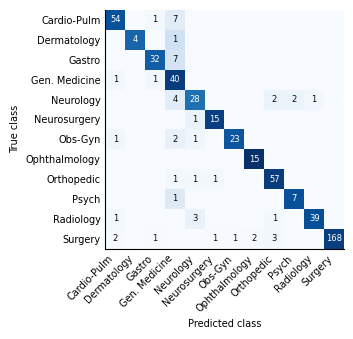

In [ ]:
fig = f.plot_confusion_matrix(y_valid, predict_combined, labels)
#fig.savefig("confusion_matrix_best_model.pdf", bbox_inches="tight")

### Best Model on Records With and Without Keywords

In [14]:
no_keywords_valid = (df.loc[valid_indices, "keywords"] == "").to_numpy()
right = predict_combined == y_valid.to_numpy()

for name, subset in [("With keywords", ~no_keywords_valid), ("Without keywords", no_keywords_valid)]:
    print(f"{name}: {right[subset].sum()}/{subset.sum()} right ({right[subset].mean():.1%})")

With keywords: 441/446 right (98.9%)
Without keywords: 41/87 right (47.1%)


In [15]:
path_test = DATA / "test_no_labels.csv"
df_test = pd.read_csv(path_test, sep=";",encoding="utf-8-sig",header=None, keep_default_na=False)
df_test.columns = ["description", "sample_name", "transcription", "keywords"]
df_test = df_test.fillna("")

df_test["transcription_headers_model"] = df_test["transcription"].apply(f.extract_headers).apply(f.headers_for_model)
df_test["transcription_headers_words"] = df_test["transcription"].apply(f.extract_headers).apply(f.headers_words)


In [16]:
input_only_keywords_test = f.build_input_variants(df_test, ["keywords"])
input_text_test = f.build_input_variants(df_test, ["description", "sample_name", "transcription", "transcription_headers_words", "transcription_headers_model"])

model_keywords_all = f.fit_pipeline(input_only_keywords, df["medical_specialty"], linear_svc)
model_text_all = f.fit_pipeline(input_text, df["medical_specialty"], logistic_regression)

no_keywords = df_test["keywords"] == ""

pred_test = np.where(no_keywords, model_text_all.predict(input_text_test), model_keywords_all.predict(input_keywords_test := input_only_keywords_test))

In [17]:
pd.Series(pred_test).to_csv("results.txt", index=False, header=False)
print(pd.Series(pred_test[no_keywords]).value_counts())

General Medicine            29
Cardiovascular-Pulmonary    11
Neurology                    8
Psychiatry-Psychology        6
Obstetrics-Gynecology        5
Neurosurgery                 4
Orthopedic                   3
Surgery                      3
Radiology                    2
Gastroenterology             1
Name: count, dtype: int64
